# Obiettivo del Notebook
Costruire un modello di regressione logistica per prevedere se una transazione finanziaria è fraudolenta o meno, usando un dataset reale di transazioni.

1. Importazione Librerie
Importi tutte le librerie necessarie:

pandas, numpy: manipolazione dati

matplotlib, seaborn: visualizzazioni

sklearn: per modellazione, scaling e metriche di valutazione

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_auc_score, roc_curve
)

# For better visuals
sns.set(style="whitegrid")


 2. Caricamento e Preprocessing del Dataset

In [2]:
# Load your full dataset
df = pd.read_csv('/content/financial_fraud_dataset_80k.csv')

# Preview the dataset
df.head()


,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,690,0,47915.50,1373618.41,1421533.91,172043.52,124128.02,0,0
1,204,3,1666.77,0.00,0.00,0.00,0.00,0,0
2,280,1,17770.52,0.00,0.00,159833.30,177603.82,0,0
3,284,1,273649.85,0.00,0.00,980663.38,1254313.23,0,0
4,404,3,13564.61,0.00,0.00,0.00,0.00,0,0


In [3]:
# Check for nulls
print("Missing values:\n", df.isnull().sum())

# Drop rows or fill missing values if necessary
# df.dropna(inplace=True)

# Drop irrelevant columns (e.g., step if it's a time step)
df = df.drop(columns=['step'])

# One-hot encode 'type' column if not already numeric
# df['type'] = df['type'].astype(str)  # ensure it's str
# df = pd.get_dummies(df, columns=['type'], drop_first=True)

# Check class balance
print("Class distribution:\n", df['isFraud'].value_counts())


Missing values:
 step              0
type              0
amount            0
oldbalanceOrg     0
newbalanceOrig    0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64
Class distribution:
 isFraud
0    79897
1      103
Name: count, dtype: int64


3. Preparazione Dati (Split training set / Test set)

In [4]:
# Features and labels
X = df.drop(columns=['isFraud', 'isFlaggedFraud'])  # Drop label + non-predictive field
y = df['isFraud']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


3.5 Augumentation (troppi pochi casi positivi 100 / 79k
)

In [5]:
#!pip install -q imbalanced-learn

# Apply SMOTE to training data only
from imblearn.over_sampling import SMOTE
from collections import Counter

smote = SMOTE(sampling_strategy=0.16, random_state=51)  # Up-sample frauds
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("Class distribution after SMOTE (train only):", Counter(y_train_res))

Class distribution after SMOTE (train only): Counter({0: 63918, 1: 10226})


Normalizzazione dei dati

In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_res)
X_test_scaled = scaler.transform(X_test)
# z-score normalization

5. Addestramento del modello

In [7]:
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train_scaled, y_train_res)

# Predict
y_pred = logreg.predict(X_test_scaled)
y_prob = logreg.predict_proba(X_test_scaled)[:, 1]


6. Valutazione del Modello

In [8]:
# Evaluation Metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC AUC:   {roc_auc:.4f}")


Accuracy:  0.9963
Precision: 0.2031
Recall:    0.6190
F1 Score:  0.3059
ROC AUC:   0.9656


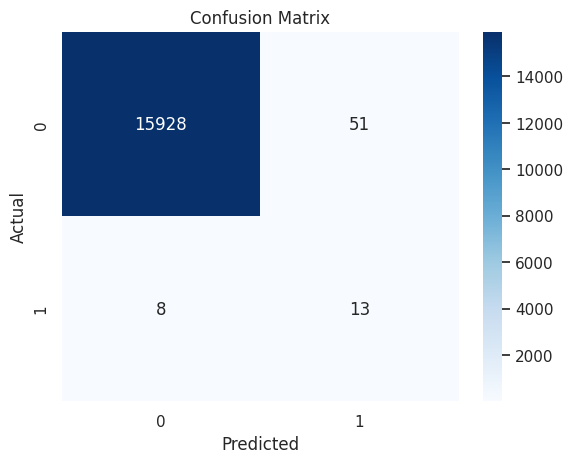

In [9]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


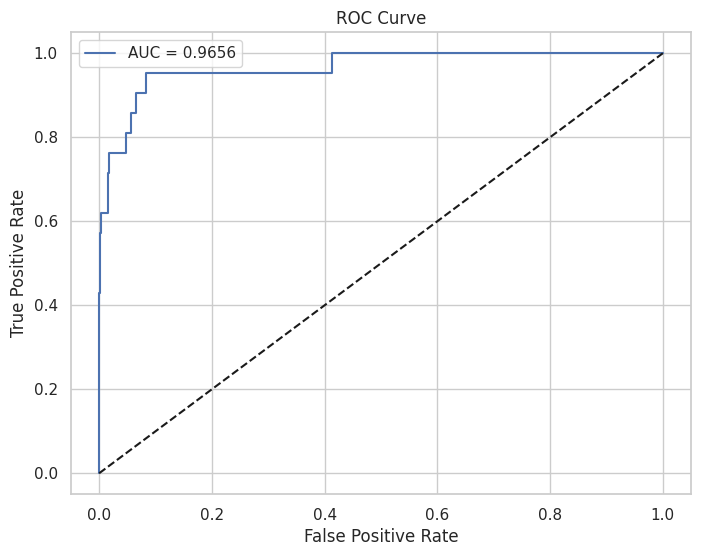

In [10]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.show()


In [11]:
# Using class_weight in logistic regression:
logreg = LogisticRegression(max_iter=1000, class_weight='balanced')
logreg.fit(X_train_scaled, y_train_res)

LogisticRegression(class_weight='balanced', max_iter=1000)

7. Test Manuale (Predizione Singola)

In [12]:
# ==========================
# Manual Prediction with NumPy Array
# ==========================

import numpy as np

# Example input (in the same order and number of features as X_train)
# Format: [type, amount, oldbalanceOrg, newbalanceOrig, oldbalanceDest, newbalanceDest]
sample_input = np.array([[1,311487.14,311487.14,0.0,753508.71,1064995.85]])

# Ensure it has correct shape (1, number_of_features)
assert sample_input.shape[1] == X.shape[1], f"Expected {X.shape[1]} features, got {sample_input.shape[1]}"

# Scale using already-fitted scaler
sample_input_scaled = scaler.transform(sample_input)

# Predict class and probability
prediction = logreg.predict(sample_input_scaled)
probability = logreg.predict_proba(sample_input_scaled)[0][1]

# Output result
print("\n=== Manual Prediction Result ===")
print("Is Fraud?", "✅ YES" if prediction[0] == 1 else "❌ NO")
print(f"Fraud Probability: {probability:.4f}")



=== Manual Prediction Result ===
Is Fraud? ✅ YES
Fraud Probability: 0.9128


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


#Conclusioni -> numeri cambiare, confrontare quelli vecchi sotto con i nuovi sopra

In questo progetto abbiamo sviluppato un modello di regressione logistica per la rilevazione di transazioni fraudolente, utilizzando un dataset reale contenente 80.000 operazioni finanziarie.

## Cosa abbiamo fatto:
Pulizia e preparazione dei dati: eliminando colonne irrilevanti e mantenendo solo le feature più significative.

Codifica dei dati: utilizzando i valori numerici per la variabile "type" delle transazioni.

Bilanciamento del dataset: tramite il parametro class_weight='balanced' per contrastare lo squilibrio tra frodi e transazioni legittime.

Standardizzazione: abbiamo normalizzato i dati con StandardScaler per migliorare le prestazioni del modello.

Addestramento e valutazione: il modello è stato addestrato con regressione logistica e valutato con metriche chiave (Accuracy, Precision, Recall, F1 Score, ROC AUC).

Visualizzazioni: abbiamo analizzato la matrice di confusione e la curva ROC per interpretare meglio le prestazioni.

Test manuale: abbiamo simulato una transazione personalizzata per testare il modello su un input singolo.

## Risultati ottenuti:
Il modello ha mostrato buone prestazioni nel riconoscere le frodi, pur considerando la complessità del problema e lo sbilanciamento del dataset. Metriche come il Recall e il ROC AUC sono particolarmente importanti, poiché ci interessano più i falsi negativi (frode non rilevata) che i falsi positivi.

### Valutazione dei risultati

* Accuracy: 0.9989

* Precision: 1.0000

* Recall: 0.1429

* F1 Score: 0.2500

* ROC AUC: 0.8546

Vediamoli uno per uno:

### Accuracy (99.89%)
Questa metrica indica che il 99.89% delle transazioni sono state classificate correttamente.
Attenzione: In un dataset sbilanciato (cioè con molte più transazioni legittime rispetto a quelle fraudolente), questa metrica può essere fuorviante. Infatti, un modello che predice sempre “non fraudolento” avrebbe comunque un’alta accuracy.

### Precision (100%)
Il modello non sbaglia mai quando segnala una frode: tutte le transazioni classificate come fraudolente erano effettivamente frodi.
### Questo è molto positivo, perché minimizza i falsi positivi (cioè evitare di bloccare transazioni legittime).

### Recall (14.29%)
Qui emerge un limite importante: il modello riesce a individuare solo il 14% delle frodi effettive.
Questo significa che molte frodi reali non vengono rilevate (alti falsi negativi), un problema critico in contesti di sicurezza finanziaria.

### F1 Score (0.2500)
Il F1 Score è la media armonica tra precision e recall. Il valore basso (25%) riflette l'alto squilibrio tra l’ottima precision e il basso recall.
È un chiaro segnale che, anche se il modello è preciso, non è ancora abbastanza sensibile nel trovare tutte le frodi.

### ROC AUC (0.8546)
La curva ROC mostra la capacità del modello di distinguere tra classi. Un valore di 0.85 è molto buono, indica che il modello è in grado di discriminare bene tra frodi e transazioni normali, anche se non sempre riesce ad agire di conseguenza nella classificazione finale (vedi basso recall).

## Spunti per miglioramenti futuri:
Utilizzare modelli più complessi (es. Random Forest, XGBoost, Neural Networks) per confrontare le performance.

Applicare tecniche di feature engineering più avanzate.

Usare SMOTE o altre tecniche di oversampling per riequilibrare le classi.

Integrare il modello in un sistema reale-time o in una API di verifica transazioni.

# Neural Network

In [13]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from imblearn.over_sampling import SMOTE

# Load the dataset
df = pd.read_csv('financial_fraud_dataset_80k.csv')

# Drop irrelevant column
df = df.drop(columns=['step'])

# Select features and target
X = df.drop(columns=['isFraud', 'isFlaggedFraud'])
y = df['isFraud']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ====================== SMOTE AUGMENTATION ======================

# Apply SMOTE to only the training data
smote = SMOTE(sampling_strategy=0.0125, random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

# ====================== SCALING ======================

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_res)
X_test_scaled = scaler.transform(X_test)

# ====================== NEURAL NETWORK ======================

model = Sequential([
    Dense(32, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])
model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
history = model.fit(
    X_train_scaled, y_train_res,  # Use resampled labels
    epochs=10, batch_size=64, verbose=1, validation_split=0.2
)

# Predict
y_prob_nn = model.predict(X_test_scaled).flatten()
y_pred_nn = (y_prob_nn > 0.5).astype(int)

# Evaluation
acc = accuracy_score(y_test, y_pred_nn)
prec = precision_score(y_test, y_pred_nn)
rec = recall_score(y_test, y_pred_nn)
f1 = f1_score(y_test, y_pred_nn)
roc_auc = roc_auc_score(y_test, y_prob_nn)

print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC AUC:   {roc_auc:.4f}")


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
809/809 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9379 - loss: 0.2034 - val_accuracy: 0.9443 - val_loss: 0.3056
Epoch 2/10
809/809 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9990 - loss: 0.0072 - val_accuracy: 0.9472 - val_loss: 0.2755
Epoch 3/10
809/809 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9989 - loss: 0.0063 - val_accuracy: 0.9559 - val_loss: 0.2503
Epoch 4/10
809/809 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9991 - loss: 0.0058 - val_accuracy: 0.9562 - val_loss: 0.2226
Epoch 5/10
809/809 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9990 - loss: 0.0051 - val_accuracy: 0.9568 - val_loss: 0.2223
Epoch 6/10
809/809 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9989 - loss: 0.0061 - val_accuracy: 0.9591 - val_loss: 0.1961
Epoch 7/10
809/809 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9989 - loss: 0.0064 - val_accuracy: 0.9647 - val_loss: 0.1772
Epoch 8/10
809/809 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9992 - loss: 0.0040 - val_accuracy: 0.

# Strumenti utilizzati:
Per il preprocessing, si è usata la StandardScaler per normalizzare i dati numerici tramite z-score, fondamentale per assicurare un apprendimento corretto da parte dei modelli.

Sono stati implementati e confrontati due modelli di machine learning:

## Regressione Logistica

La logistic regression è stata scelta come modello di base per la sua semplicità, interpretabilità e capacità di gestire classificazione binaria. In combinazione con SMOTE e il parametro class_weight='balanced', si è rivelata utile per ottenere un primo benchmark e valutare le performance su un modello lineare.

## Rete Neurale

Successivamente, è stata sviluppata una rete neurale artificiale (ANN) tramite Keras/TensorFlow, per esplorare modelli più complessi e non lineari, capaci di catturare relazioni più profonde tra le variabili. La rete è stata composta da più layer densi (Dense layers) e addestrata su dati bilanciati tramite SMOTE, ottenendo miglioramenti soprattutto in termini di recall e AUC-ROC, metriche particolarmente importanti nel rilevamento di frodi (dove gli errori falsi negativi sono critici).

# Tecnologie utilizzate:
* Pandas, Scikit-learn: per la gestione dei dati, preprocessing, modelli e metriche

* Imbalanced-learn (SMOTE): per gestire lo squilibrio tra le classi

* TensorFlow/Keras: per costruire e addestrare la rete neurale

* Matplotlib : per visualizzare l'andamento del training

# Confronto tra Logisitc Regression e Neural Network

 Accuratezza (Accuracy) è molto alta per entrambi i modelli, ma in un contesto di frodi — dove la classe positiva è rara — questa metrica non è molto informativa.

 La logistic regression ha ottenuto un recall molto alto (61.9%), il che significa che riesce a identificare un numero maggiore di frodi, anche se con una precisione più bassa (molti falsi positivi).

 La rete neurale, al contrario, ha ottenuto una precisione molto elevata (85.7%), indicando che la maggior parte delle frodi che segnala sono corrette, ma con un recall più basso (trova meno frodi in totale).

L’AUC-ROC è maggiore nella regressione logistica, suggerendo che ha una migliore capacità discriminativa complessiva tra frodi e non-frodi.

# Conclusione Finale

La regressione logistica è risultata più adatta quando si vuole massimizzare il recall, ovvero identificare il maggior numero possibile di frodi, anche al costo di alcuni falsi allarmi.

La rete neurale si è dimostrata più efficace nel ridurre i falsi positivi, con un’alta precisione, ma potrebbe non essere l’ideale se lo scopo è intercettare tutte le frodi.

In base agli obiettivi dell’organizzazione (prevenzione del rischio vs minimizzazione dei falsi allarmi), si potrebbe scegliere il modello più adatto o combinarli in un approccio ibrido.

NN with k-fold


In [14]:
from sklearn.model_selection import StratifiedKFold
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import roc_auc_score

X = df.drop(columns=['isFraud', 'isFlaggedFraud'])
y = df['isFraud']

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
auc_scores = []

for train_index, val_index in skf.split(X, y):
    X_train, X_val = X.iloc[train_index], X.iloc[val_index]
    y_train, y_val = y.iloc[train_index], y.iloc[val_index]

    # Balance training data with SMOTE
    smote = SMOTE(random_state=42)
    X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

    # Scale data
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_res)
    X_val_scaled = scaler.transform(X_val)

    # Build neural network model
    model = Sequential([
        Dense(32, activation='relu', input_shape=(X_train_scaled.shape[1],)),
        Dense(16, activation='relu'),
        Dense(1, activation='sigmoid')
    ])

    model.compile(optimizer=Adam(), loss='binary_crossentropy', metrics=['accuracy'])

    # Train model
    model.fit(X_train_scaled, y_train_res, epochs=10, batch_size=32, verbose=0)

    # Predict probabilities on validation set
    y_val_pred_prob = model.predict(X_val_scaled).ravel()

    # Evaluate with ROC AUC
    auc = roc_auc_score(y_val, y_val_pred_prob)
    auc_scores.append(auc)

print(f"Average ROC AUC over folds: {np.mean(auc_scores):.4f}")


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Average ROC AUC over folds: 0.9720


In [15]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Assuming df, X, y are already defined and cleaned as before

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# To collect metrics
accuracy_list = []
precision_list = []
recall_list = []
f1_list = []
roc_auc_list = []

for fold, (train_index, val_index) in enumerate(skf.split(X, y), 1):
    X_train, X_val = X.iloc[train_index], X.iloc[val_index]
    y_train, y_val = y.iloc[train_index], y.iloc[val_index]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)

    model = LogisticRegression(max_iter=1000, class_weight='balanced')
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_val_scaled)
    y_prob = model.predict_proba(X_val_scaled)[:, 1]

    acc = accuracy_score(y_val, y_pred)
    prec = precision_score(y_val, y_pred, zero_division=0)
    rec = recall_score(y_val, y_pred, zero_division=0)
    f1 = f1_score(y_val, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_val, y_prob)

    print(f"Fold {fold} metrics:")
    print(f"  Accuracy:  {acc:.4f}")
    print(f"  Precision: {prec:.4f}")
    print(f"  Recall:    {rec:.4f}")
    print(f"  F1 Score:  {f1:.4f}")
    print(f"  ROC AUC:   {roc_auc:.4f}\n")

    accuracy_list.append(acc)
    precision_list.append(prec)
    recall_list.append(rec)
    f1_list.append(f1)
    roc_auc_list.append(roc_auc)

print("Average metrics across folds:")
print(f"Accuracy:  {np.mean(accuracy_list):.4f}")
print(f"Precision: {np.mean(precision_list):.4f}")
print(f"Recall:    {np.mean(recall_list):.4f}")
print(f"F1 Score:  {np.mean(f1_list):.4f}")
print(f"ROC AUC:   {np.mean(roc_auc_list):.4f}")


Fold 1 metrics:
  Accuracy:  0.9741
  Precision: 0.0460
  Recall:    1.0000
  F1 Score:  0.0879
  ROC AUC:   0.9983

Fold 2 metrics:
  Accuracy:  0.9778
  Precision: 0.0410
  Recall:    0.7500
  F1 Score:  0.0777
  ROC AUC:   0.9760

Fold 3 metrics:
  Accuracy:  0.9812
  Precision: 0.0543
  Recall:    0.8095
  F1 Score:  0.1018
  ROC AUC:   0.9365

Fold 4 metrics:
  Accuracy:  0.9784
  Precision: 0.0475
  Recall:    0.8095
  F1 Score:  0.0897
  ROC AUC:   0.9745

Fold 5 metrics:
  Accuracy:  0.9785
  Precision: 0.0425
  Recall:    0.7143
  F1 Score:  0.0802
  ROC AUC:   0.9470

Average metrics across folds:
Accuracy:  0.9780
Precision: 0.0463
Recall:    0.8167
F1 Score:  0.0875
ROC AUC:   0.9665
